In [16]:
%pip install matplotlib numpy scipy opencv-python

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
    --------------------------------------- 0.8/44.0 MB 2.2 MB/s eta 0:00:20
   - -------------------------------------- 1.3/44.0 MB 2.2 MB/s eta 0:00:20
   - -------------------------------------- 1.8/44.0 MB 2.3 MB/s eta 0:00:19
   -- ------------------------------------- 2.6/44.0 MB 2.7 MB/s eta 0:00:16
   --- ------------------------------------ 3.4/44.0 MB 2.8 MB/s eta 0:00:15
   --- ------------------------------------ 3.9/44.0 MB 2.8 MB/s eta 0:00:15
   ---- ----------------------------------- 4.5/44.0 MB 2.9 MB/s eta 0:00:14
   ---- ----------------------------------- 5.2/44.0 MB 2.9 MB/s eta 0:00:14
   ----- ---------------------------------- 6.0/44.0 MB 3.0 MB/s eta 0:00:13
   ------ --------------------------------- 6.8/44.0 MB 3.1 MB/s eta 0:00:13
   ------ --------------------------------- 7.6/44.0 MB 3.2 MB/s eta 0:00:12
   -------- -

In this noteobook we aim to demonstrate the method of inverse filtering.

For this we assume that the distorted image follows the form:

$$g(x, y) = H[f(x, y)] + n(x, y)$$

Where H is the degradation model and n(x, y) is added noise. If we assume this model is linear and position invariant (which is a good approximation for various types of real life scenarios), we can then take the DFT of both sides to get:

$$

G(u, v) = H(u, v) \cdot F(u, v) + N(u, v)

$$

In order to eliminate the effects of the distortion model, we can obtain back f(x, y) by taking the IDFT of the signal:

$$

F(u, v) = \frac{G(u, v) - N(u, v)}{H(u, v)}

$$


If the noise is now and we know the degradation model, then we can perfectly restore the original image. However, if the noise term is present then the noise spectrum divided by the degradation model can diverge for values where the degradation model equals zero. This is happens more often than not considering most degradation models are variants of low pass filters. In order to overcome this, we will analyze a more generalized model later on.

In [70]:
IMG_PATH = 'walk.jpg'

In [71]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sp
import cv2

In [72]:
def ShowImage(image, title=''):
    plt.imshow(image, cmap='gray')
    plt.title(title)
    plt.axis('off')
    plt.show()

In [73]:
def MotionBlurKernel(size, angle):
    # Create a motion blur kernel of given size and angle
    kernel = np.zeros((size, size))
    center = size // 2
    angle_rad = np.deg2rad(angle)
    
    for i in range(size):
        x = int(center + (i - center) * np.cos(angle_rad))
        y = int(center + (i - center) * np.sin(angle_rad))
        if 0 <= x < size and 0 <= y < size:
            kernel[y, x] = 1
            
    kernel /= np.sum(kernel)  # Normalize the kernel
    return kernel

In [190]:
def GaussianBlurKernel(size, sigma):
    # Create a Gaussian blur kernel of given size and sigma
    ax = np.linspace(-(size // 2), size // 2, size)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    kernel /= np.sum(kernel)  # Normalize the kernel
    return kernel

In [74]:
def ApplyDegradation(image, kernel):
    # Apply degradation to the image using the given kernel
    degraded_image = cv2.filter2D(image, -1, kernel)
    return degraded_image

In [75]:
def AddGaussianNoise(image, mean=0, std=10):
    # Add Gaussian noise to the image
    noise = np.random.normal(mean, std, image.shape)
    noisy_image = image + noise
    noisy_image = np.clip(noisy_image, 0, 255)  # Clip values to valid range
    return noisy_image

In [205]:
def InverseFilter(degraded_image, kernel, threshold=1e-3):
    # Apply inverse filtering to the degraded image
    kernel_fft = np.fft.fft2(kernel, s=degraded_image.shape)
    #ShowImage(np.abs(kernel_fft), title='Kernel FFT Magnitude')
    print(np.max(kernel_fft))
    degraded_fft = np.fft.fft2(degraded_image)
    #ShowImage(20 * np.log(np.abs(degraded_fft) + 1e-10), title='Degraded Image FFT Magnitude')
    
    restored_fft = np.where(np.abs(kernel_fft) > threshold, degraded_fft / kernel_fft, 0)
    restored_image = np.abs(np.fft.ifft2(restored_fft))

    #ShowImage(20 * np.log(np.abs(restored_fft) + 1e-10), title='Restored Image FFT Magnitude')

    # Clip values to valid range
    restored_image = np.clip(restored_image, 0, 255)
    return restored_image

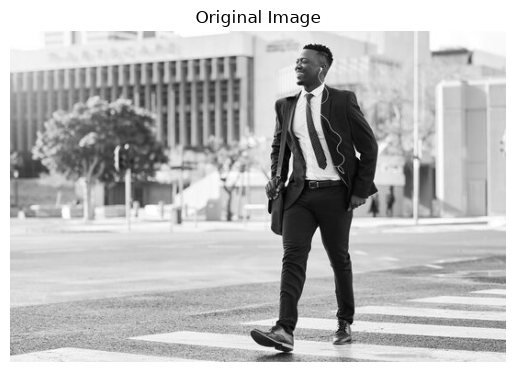

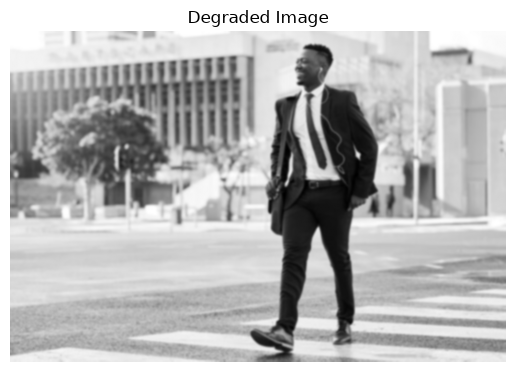

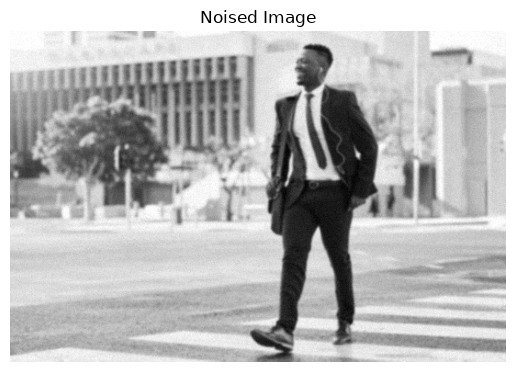

(1+0j)


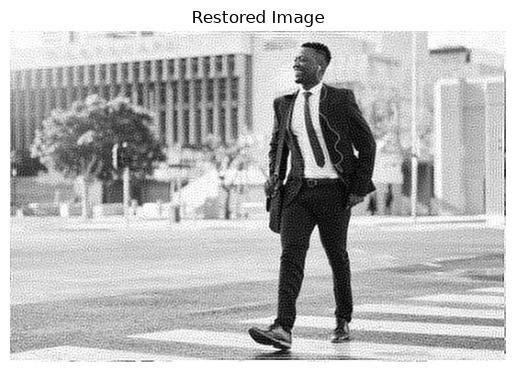

In [211]:
image = plt.imread(IMG_PATH)

# Greyscale conversion if the image is RGB
if image.ndim == 3:
    image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

#convert image to float64 for processing
image = image.astype(np.float64)

ShowImage(image, 'Original Image')

#degradation_model = MotionBlurKernel(10, 45)

degradation_model = GaussianBlurKernel(5, 1.0)

degraded_image = ApplyDegradation(image, degradation_model)

ShowImage(degraded_image, 'Degraded Image')

noised_image = AddGaussianNoise(degraded_image, 0, 5)

ShowImage(noised_image, 'Noised Image')

restored_image = InverseFilter(noised_image, degradation_model, threshold=0.1)

ShowImage(restored_image, 'Restored Image')